# Mixed-species group properties: MODEL (group size 16, 8 + 8 fish)

Three figures with the same layout, one per model file in `Data`:
`model_mixed_species.h5` (fitted cross-species weights), `model_mixed_species_w0.h5` (all cross-species weights 0) and `model_mixed_species_w1.h5` (all 1).
Columns = pairs TB (A) - RB (B), BPT (A) - ST (B), NT (A) - ST (B), NT (A) - RET (B) (species A = first species); rows:

1. **Interaction strengths**, conspecific ($\hat\mu_{AA}, \hat\mu_{BB}$, x) vs heterospecific ($\hat\mu_{AB}, \hat\mu_{BA}$, y) for speed matching (circle), alignment (square) and attraction (triangle):
   $\hat\mu^{c}_{ij} = w^{c}_{ij}\,\mu^{c}_i/\mu_{0,i}$ ($c$ = sm, al) and $\hat\mu^{\mathrm{at}}_{ij} = \sqrt{w^{\mathrm{at}}_{ij}\,\mu^{\mathrm{at}}_i}/\mu_{0,i}$, with $w_{ii} = 1$; parameters and weights are read from the h5 file. Grey: heterospecific > conspecific.
2. **Individual speed** of the two species subgroups (solid) and the entire group (dotted), with box plots.
3. **Group polarization** of the subgroups, the entire group and 8 fish chosen at random in every frame (dashed grey).
4. **Subgroup centroid distance**, observed (black) vs a null of random 8 + 8 splits of the group (grey, one split per frame), 100 bins from 0 to 1.2 x the 99.5th percentile (at most 40 BL), with box plots (first figure: same x ranges as the data figure, 0-12, 0-12, 0-40, 0-30 BL).

Frames before the transient (`transient_s`) are dropped. Saved in `Results` as PNG and PDF (300 dpi).

## 1. Settings and functions

In [1]:
%matplotlib inline
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"]})

DATA, OUT = os.path.join("..", "Data"), os.path.join("..", "Results")
PAIRS = [("TB", "RB"), ("BPT", "ST"), ("NT", "ST"), ("NT", "RET")]            # (species A, species B), one column each
COL = {"A": "#E69F00", "B": "#0072B2", "ALL": "k", "obs": "k", "null": "grey", "rand8": "grey"}
D_EDGES = np.arange(0, 40 + 1e-9, 0.01)                                     # fine centroid-distance bins (BL)
FONT, TICK_FONT, lw = 15, 12, 1.8                                           # labels (pt), ticks (pt), line width
rng = np.random.default_rng(0)                                              # random 8 fish

def rel_hist(ax, x, edges, **kw):
    """Step histogram of the probability density; returns the bar heights."""
    return ax.hist(x, bins=edges, density=True, histtype="step", **kw)[0]


def visible_max(h, edges, xl):
    """Tallest bar inside the x range xl."""
    return h[(edges[:-1] < xl[1]) & (edges[1:] > xl[0])].max()


def set_y_to_max(ax, ymax):
    """y axis from 0 to the tallest bar; whole-number ticks in 2-3 equal steps when ymax >= 2, otherwise 0, ymax/2, ymax."""
    ax.set_ylim(0, ymax)
    if ymax >= 2:
        top = int(ymax)
        while top % 2 and top % 3: top -= 1
        yt = list(range(0, top + 1, top // 2 if top % 2 == 0 else top // 3))
        ax.set_yticks(yt); ax.set_yticklabels(map(str, yt))
    else:
        d = 1 if ymax >= 0.2 else 2 if ymax >= 0.02 else 3 if ymax >= 0.002 else 4   # decimals of the tick labels
        ax.set_yticks([0, ymax / 2, ymax]); ax.set_yticklabels(["0", f"{ymax / 2:.{d}f}", f"{ymax:.{d}f}"])


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=TICK_FONT)


def box_stats(x, label):
    q1, med, q3 = np.percentile(x, [25, 50, 75]); iqr = q3 - q1
    return dict(label=label, med=med, q1=q1, q3=q3, fliers=[], whislo=x[x >= q1 - 1.5 * iqr].min(), whishi=x[x <= q3 + 1.5 * iqr].max())


def box_stats_from_counts(counts, edges, label):
    """Box-plot statistics of values stored as histogram counts on `edges`."""
    cdf = np.concatenate([[0.0], np.cumsum(counts) / np.sum(counts)])
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, edges); iqr = q3 - q1
    nz = np.nonzero(counts)[0]
    return dict(label=label, med=med, q1=q1, q3=q3, fliers=[],
                whislo=max(q1 - 1.5 * iqr, edges[nz[0]]), whishi=min(q3 + 1.5 * iqr, edges[nz[-1] + 1]))


def draw_box(axb, stats, colors):
    """Horizontal box plots (no outliers) under a histogram."""
    bp = axb.bxp(stats, vert=False, showfliers=False, widths=0.65, patch_artist=True, medianprops=dict(color="k", lw=lw * 0.8))
    for box, c in zip(bp["boxes"], colors):
        box.set_facecolor(c); box.set_alpha(0.6)
    axb.invert_yaxis(); axb.set_yticks([])
    axb.spines[["top", "right", "left"]].set_visible(False)
    axb.tick_params(labelsize=TICK_FONT)


def hist_and_box(fig, spec, hist_h, box_h):
    """A histogram axis with a box-plot axis below it (shared x)."""
    inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=spec, height_ratios=[hist_h, box_h], hspace=0.2 / hist_h)
    ax = fig.add_subplot(inner[0])
    return ax, fig.add_subplot(inner[1], sharex=ax)


def polarization(vel, mask=None):
    """Length of the mean unit heading of the fish in `mask` (all if None) per frame; NaN if fewer than 75 % of them have a heading."""
    mask = np.ones(vel.shape[:2], bool) if mask is None else mask
    speed = np.linalg.norm(vel, axis=2)
    ok = np.isfinite(speed) & (speed > 1e-9) & mask
    u = np.where(ok[..., None], vel / np.where(ok, speed, 1.0)[..., None], 0.0)
    n = ok.sum(1)
    P = np.linalg.norm(u.sum(1), axis=1) / np.maximum(n, 1)
    P[n < np.maximum(2, np.ceil(0.75 * mask.sum(1)))] = np.nan
    return P


def mu_hat(a):
    """Interaction strengths {(i, c): (conspecific, heterospecific)} of one pair from its h5 attributes."""
    out = {}
    for i, j in (("A", "B"), ("B", "A")):
        m0 = a[f"{i}_mu0"]
        for c in ("sm", "al", "at"):
            mu, w = a[f"{i}_mu_{c}"], a[f"w_{c}_{i}{j}"]
            out[i, c] = (np.sqrt(mu) / m0, np.sqrt(w * mu) / m0) if c == "at" else (mu / m0, w * mu / m0)
    return out


def load_model(path):
    """Speed, polarization, centroid-distance histograms (observed, null) and interaction strengths of every pair."""
    res = {}
    with h5py.File(path, "r") as h5:
        for a, b in PAIRS:
            g = h5[f"{a}_{b}"]
            assert g.attrs["A"] == a                                        # species 0 = species A
            rng_cd = np.random.default_rng(0)                               # null: one random 8 + 8 split per frame
            r = dict(speed_A=[], speed_B=[], pol=[], pol_A=[], pol_B=[], pol_rand8=[], h_d=0, h_null=0, mu=mu_hat(g.attrs))
            for run in g.values():
                keep = run["t"][:] > g.attrs["transient_s"]                 # drop the initial transient
                v, phi, x, y = (run[k][:][keep].astype(float) for k in ("v", "phi", "x", "y"))
                vel = v[..., None] * np.stack([np.cos(phi), np.sin(phi)], axis=2)
                is_a = np.tile(run["species"][:] == 0, (len(v), 1))
                rand8 = rng.permuted(np.tile(np.arange(16) < 8, (len(v), 1)), axis=1)
                for k, val in (("speed_A", v[is_a]), ("speed_B", v[~is_a]), ("pol", polarization(vel)), ("pol_A", polarization(vel, is_a)),
                               ("pol_B", polarization(vel, ~is_a)), ("pol_rand8", polarization(vel, rand8))):
                    r[k].append(val)
                cd = lambda iA, iB: np.hypot(np.take_along_axis(x, iA, 1).mean(1) - np.take_along_axis(x, iB, 1).mean(1),
                                             np.take_along_axis(y, iA, 1).mean(1) - np.take_along_axis(y, iB, 1).mean(1))
                order = np.tile(np.argsort(~is_a[0], kind="stable"), (len(v), 1))  # species A first, then B
                perm = rng_cd.permuted(np.tile(np.arange(16), (len(v), 1)), axis=1)
                r["h_d"] = r["h_d"] + np.histogram(cd(order[:, :8], order[:, 8:]), D_EDGES)[0]
                r["h_null"] = r["h_null"] + np.histogram(cd(perm[:, :8], perm[:, 8:]), D_EDGES)[0]
            for k in ("speed_A", "speed_B", "pol", "pol_A", "pol_B", "pol_rand8"):
                r[k] = (lambda z: z[np.isfinite(z)])(np.concatenate(r[k]))
            r["speed_all"] = np.concatenate([r["speed_A"], r["speed_B"]])
            res[(a, b)] = r
    return res


def rebin(h, xmax, n=100):
    """Fine histogram on D_EDGES -> (centres, density) of n equal bins on [0, xmax], normalised by all counts."""
    e = np.linspace(0, xmax, n + 1)
    C = np.interp(e, D_EDGES, np.r_[0.0, np.cumsum(h)])
    return (e[1:] + e[:-1]) / 2, np.diff(C) / (h.sum() * np.diff(e))


def add_column_titles(axes, fontsize=11, pad_in=0.06):
    """Bold two-colour titles 'TB (A) - RB (B)' above the top row; returns their height (in)."""
    fig = axes[0].figure
    fig.canvas.draw()
    r, W_px, H = fig.canvas.get_renderer(), fig.get_figwidth() * fig.dpi, fig.get_figheight()
    for ax, (a, b) in zip(axes, PAIRS):
        bb = ax.get_position()
        ts = [fig.text(0, bb.y1 + pad_in / H, s, color=c, fontsize=fontsize, fontweight="bold", va="bottom")
              for s, c in ((f"{a} (A)", COL["A"]), ("-", "k"), (f"{b} (B)", COL["B"]))]
        w, gap = [t.get_window_extent(r).width for t in ts], 0.3 * fontsize * fig.dpi / 72
        x = (bb.x0 + bb.x1) / 2 * W_px - (sum(w) + 2 * gap) / 2
        for t, wi in zip(ts, w):
            t.set_x(x / W_px); x += wi + gap
    return pad_in + 1.25 * fontsize / 72

## 2. Figure function

In [2]:
WIDTH, FIG_H, BOX_RATIO = 8.27, 11.69 / 2 + 0.10, 0.22       # A4 width; height of rows 2-4 incl. margins; box-plot / histogram height
SPEED_XLIM = [(0, 25), (0, 12.5), (0, 11.5), (0, 10)]          # same as the data figure
XLABELS = ["Model individual speed (BL/s)", "Model group polarization", "Model subgroup centroid distance (BL)"]
MU_MARKERS = {"sm": ("o", "Speed matching"), "al": ("s", "Alignment"), "at": ("^", "Attraction")}


def make_figure(res, out_name, left=1.25, cd_legend=None, cd_xlim=None):
    """4 x 4 figure for one model file. left: left margin (in); cd_legend: position / size of the Observed-Null legend;
    cd_xlim: centroid-distance x range per column (None = automatic, 1.2 x the 99.5th percentile, at most 40 BL)."""
    L, R, T, B, GAP, GAP_TOP = left, 1.0, 0.72, 1.3, 0.78, 2.03     # margins and gaps (in)
    hist_h = (FIG_H - T - B - 2 * GAP - 0.15) / (3 + 3 * BOX_RATIO); box_h = BOX_RATIO * hist_h
    row_h = hist_h + box_h + 0.05
    TOP_H = (WIDTH - L - R) / (4 + 3 * 0.55)                          # square panels of the top row
    H = T + B + 3 * row_h + 2 * GAP + TOP_H + GAP_TOP
    fig = plt.figure(figsize=(WIDTH, H))
    kw = dict(figure=fig, wspace=0.55, left=L / WIDTH, right=1 - R / WIDTH)
    top_gs = GridSpec(1, 4, bottom=1 - (T + TOP_H) / H, top=1 - T / H, **kw)
    outer = GridSpec(3, 4, hspace=GAP / row_h, bottom=B / H, top=1 - (T + TOP_H + GAP_TOP) / H, **kw)

    # row 1: interaction strengths, conspecific (x) vs heterospecific (y)
    top_axes = [fig.add_subplot(top_gs[0, j]) for j in range(4)]
    for ax, ab in zip(top_axes, PAIRS):
        P = res[ab]["mu"]
        lim = max(v for xy in P.values() for v in xy) + 1             # equal x and y limits: largest value + 1
        ax.fill_between([0, lim], [0, lim], lim, color="0.85", lw=0, zorder=0)
        ax.plot([0, lim], [0, lim], color="k", lw=1.2, zorder=1)
        for (i, c), xy in P.items():                                  # circles on top of squares, so overlapping points stay visible
            ax.plot(*xy, MU_MARKERS[c][0], mfc=COL[i], mec="k", mew=0.8, ms=9, alpha=0.6, zorder={"al": 2, "at": 3, "sm": 4}[c], clip_on=False)
        ax.set(xlim=(0, lim), ylim=(0, lim), aspect="equal")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(MaxNLocator(nbins=2, integer=True, steps=[1, 2, 5, 10]))
        style(ax)
    top_axes[0].set_ylabel(r"$\hat{\mu}_{AB},\ \hat{\mu}_{BA}$", fontsize=FONT, labelpad=4)
    y0 = top_axes[0].get_position().y0
    fig.text(0.5 * (top_axes[0].get_position().x0 + top_axes[-1].get_position().x1), y0 - 0.34 / H, r"$\hat{\mu}_{AA},\ \hat{\mu}_{BB}$",
             ha="center", va="top", fontsize=FONT)
    leg = dict(loc="upper center", frameon=False, fontsize=FONT, handletextpad=0.3, columnspacing=1.5, borderaxespad=0)
    fig.legend(handles=[Line2D([], [], marker="o", ls="none", mfc=COL[i], mec="k", mew=0.8, ms=9, label=f"Species {i}") for i in "AB"],
               ncol=2, bbox_to_anchor=(0.5, y0 - 0.80 / H), **leg)
    fig.legend(handles=[Line2D([], [], marker=m, ls="none", mfc="white", mec="k", mew=1.0, ms=9, label=l) for m, l in MU_MARKERS.values()],
               ncol=3, bbox_to_anchor=(0.5, y0 - 1.12 / H), **leg)

    # rows 2-4: speed, polarization, centroid distance (histogram + box plots)
    axes = [[hist_and_box(fig, outer[i, j], hist_h, box_h) for j in range(4)] for i in range(3)]
    for j, (a, b) in enumerate(PAIRS):
        r = res[(a, b)]
        ax, axb = axes[0][j]                                          # speed
        p995 = np.percentile(r["speed_all"], 99.5)
        edges, xl = np.arange(0, r["speed_all"].max() + p995 / 50, p995 / 50), SPEED_XLIM[j]
        hs = [rel_hist(ax, r[k], edges, color=c, ls=ls, lw=w) for k, c, ls, w in
              (("speed_all", "k", ":", lw * 1.2), ("speed_A", COL["A"], "-", lw), ("speed_B", COL["B"], "-", lw))]
        ax.set_xlim(*xl); set_y_to_max(ax, max(visible_max(h, edges, xl) for h in hs))
        draw_box(axb, [box_stats(r["speed_A"], a), box_stats(r["speed_B"], b)], [COL["A"], COL["B"]])
        axb.locator_params(axis="x", nbins=3, integer=True)
        ax, axb = axes[1][j]                                          # polarization
        edges = np.arange(0, 1.0125, 0.025)
        hs = [rel_hist(ax, r[k], edges, color=c, ls=ls, lw=w) for k, c, ls, w in
              (("pol", "k", ":", lw * 1.2), ("pol_A", COL["A"], "-", lw), ("pol_B", COL["B"], "-", lw), ("pol_rand8", COL["rand8"], "--", lw))]
        ax.set_xlim(0, 1); set_y_to_max(ax, max(h.max() for h in hs))
        draw_box(axb, [box_stats(r["pol_A"], a), box_stats(r["pol_B"], b)], [COL["A"], COL["B"]])
        axb.set_xticks([0, 0.5, 1]); axb.set_xticklabels(["0", "0.5", "1"])
        ax, axb = axes[2][j]                                          # centroid distance, observed vs null
        q995 = [np.interp(0.995, np.cumsum(r[k]) / np.sum(r[k]), D_EDGES[1:]) for k in ("h_d", "h_null")]   # 99.5th percentiles
        dmax = cd_xlim[j][1] if cd_xlim else min(1.2 * max(q995), D_EDGES[-1])
        curves = [(rebin(r[k], dmax), c) for k, c in (("h_null", COL["null"]), ("h_d", COL["obs"]))]
        for (xc, p), c in curves:
            ax.plot(xc, p, color=c, lw=lw * 1.3)
        ax.set_xlim(0, dmax); set_y_to_max(ax, max(p.max() for (_, p), _ in curves))
        draw_box(axb, [box_stats_from_counts(r["h_null"], D_EDGES, "Null"), box_stats_from_counts(r["h_d"], D_EDGES, "Observed")],
                 [COL["null"], COL["obs"]])
        axb.set_xticks([0, dmax / 2, dmax]) if cd_xlim else axb.xaxis.set_major_locator(MaxNLocator(nbins=3))   # fixed or automatic ticks
    for i, row in enumerate(axes):
        for ax, axb in row:
            style(ax); ax.tick_params(labelbottom=False)
        p0, p1 = row[0][1].get_position(), row[-1][1].get_position()
        fig.text((p0.x0 + p1.x1) / 2, p0.y0 - 0.34 / H, XLABELS[i], ha="center", va="top", fontsize=FONT)
    top, bot = axes[0][0][0].get_position().y1, axes[2][0][1].get_position().y0
    fig.text(0.55 / WIDTH, (top + bot) / 2, "Probability density function", rotation=90, ha="left", va="center", fontsize=FONT)

    # legends, column titles and labels a-d, row labels i-iv
    line = lambda c, ls, lab, w=lw: Line2D([], [], color=c, ls=ls, lw=w, label=lab)
    fig.legend(handles=[line(COL["A"], "-", "Species A subgroup"), line("k", ":", "Entire group", lw * 1.2), line(COL["B"], "-", "Species B subgroup"),
                        line(COL["rand8"], "--", "Random subgroup")], loc="lower center", bbox_to_anchor=(0.5, 0.02 / H), ncol=2, frameon=False,
               fontsize=FONT, handlelength=1.4, handletextpad=0.4, labelspacing=0.25, columnspacing=1.0, borderaxespad=0)
    axes[2][0][0].legend(handles=[line(COL["obs"], "-", "Observed", lw * 1.3), line(COL["null"], "-", "Null", lw * 1.3)], frameon=False,
                         handletextpad=0.3, labelspacing=0.2, borderpad=0, borderaxespad=0,
                         **(dict(loc="upper right", bbox_to_anchor=(1.04, 1.04), fontsize=10, handlelength=1.0) | (cd_legend or {})))
    title_h = add_column_titles(top_axes)
    for ax, letter in zip(top_axes, "abcd"):
        bb = ax.get_position()
        fig.text((bb.x0 + bb.x1) / 2, bb.y1 + (title_h + 0.03) / H, letter, ha="center", va="bottom", fontsize=FONT, fontweight="bold")
    for ax, numeral in zip([top_axes[0]] + [row[0][0] for row in axes], ["i", "ii", "iii", "iv"]):
        bb = ax.get_position()
        fig.text(0.1 / WIDTH, (bb.y0 + bb.y1) / 2, numeral, ha="left", va="center", fontsize=FONT, fontweight="bold")
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(OUT, f"{out_name}.{ext}"), dpi=300)
    plt.show()

## 3. The three figures

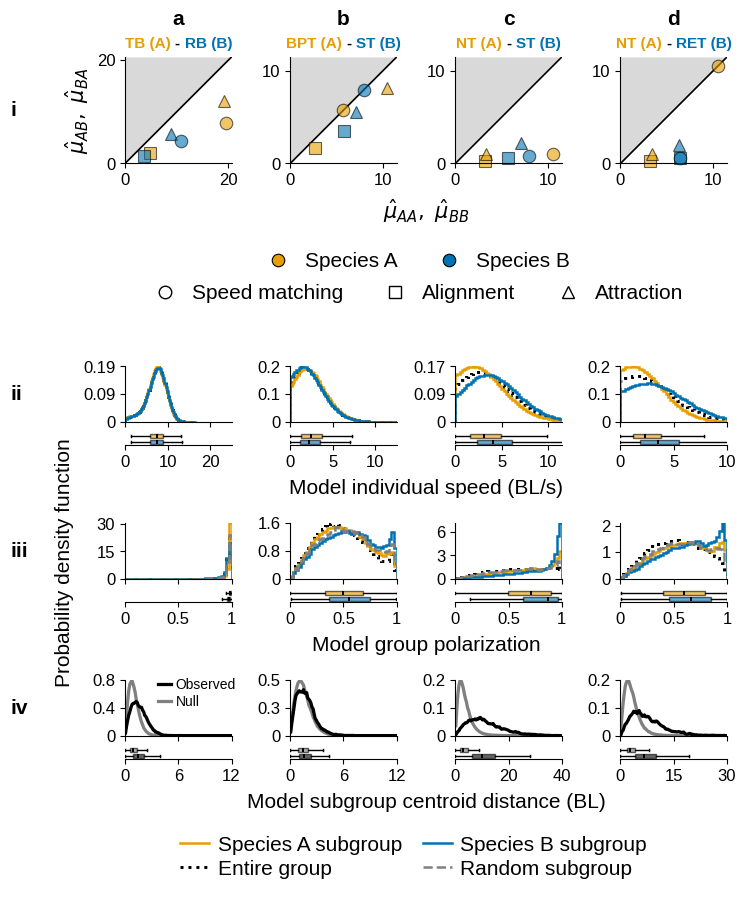

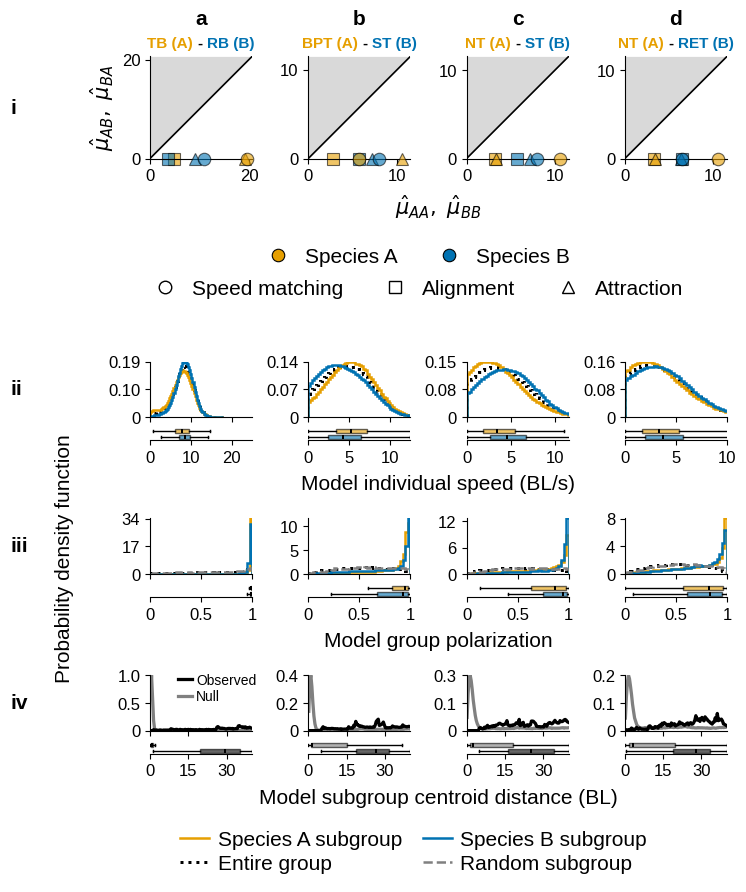

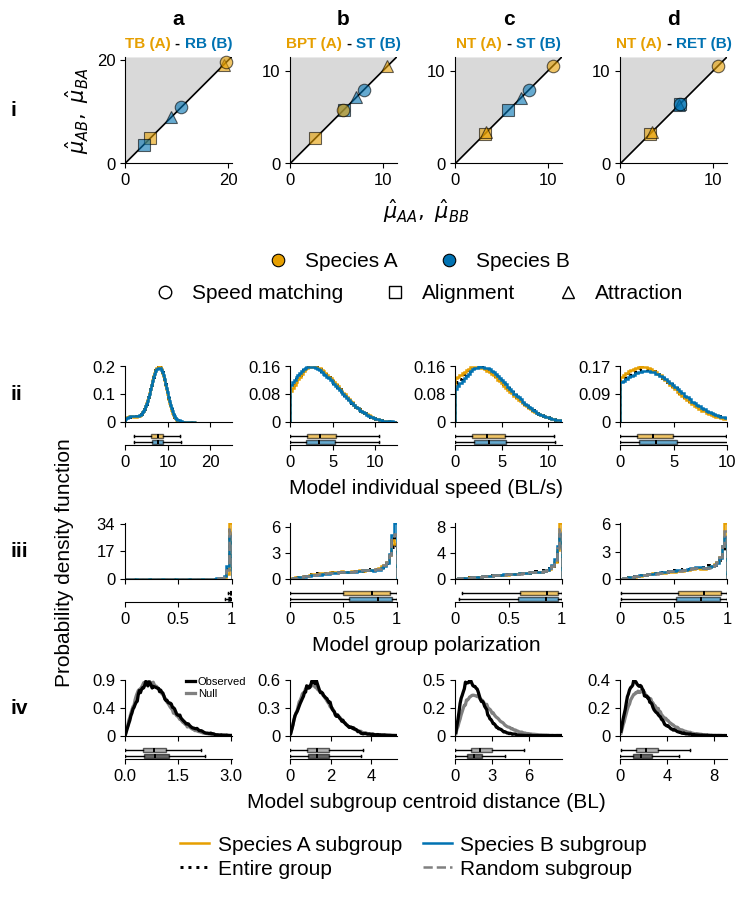

In [3]:
make_figure(load_model(os.path.join(DATA, "model_mixed_species.h5")), "mixed_species_model_group_properties_gs16",
            cd_xlim=[(0, 12), (0, 12), (0, 40), (0, 30)])                         # same centroid-distance x ranges as the data figure
make_figure(load_model(os.path.join(DATA, "model_mixed_species_w0.h5")), "mixed_species_model_w0_group_properties_gs16", left=1.5)
make_figure(load_model(os.path.join(DATA, "model_mixed_species_w1.h5")), "mixed_species_model_w1_group_properties_gs16",
            cd_legend=dict(bbox_to_anchor=(1.14, 1.06), fontsize=8, handlelength=0.8))      # legend moved right: clear of the curves